# Invisible Primes: Default Risk and Mispricing

LendingClub plays the role of the "selling bank": it assigns each loan a grade and an interest rate, which is its price for the borrower's risk. This notebook asks two questions from the point of view of a buyer of those loans:

1. **Default view:** are there borrowers graded as subprime (grades D–G) whose actual default risk is comparable to prime borrowers (grades A–B)?
2. **Pricing view:** are there loans whose interest rate is higher than their true risk justifies, so that buying them earns more than buying loans at random?

Approach:

- Use LendingClub's grade on its own as the benchmark ("the seller's view of risk").
- Train a default model on borrower information only, and a second model that also sees the grade and interest rate ("the buyer's view of risk").
- Check whether the models can separate good from bad loans *within the same grade*. If they cannot, there is nothing to buy cheap.
- Use the buyer's model to flag invisible primes and mispriced loans in the test period, then check what actually happened to them.

In [1]:
# Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

In [2]:
train = pd.read_csv(
    "22121477/train_lending_club.csv"
)

test = pd.read_csv(
    "22121477/test_lending_club.csv"
)

loan_status_labeled = test["loan_status"].notna()
test = test.loc[loan_status_labeled].copy()

print("Train issue dates:", train["issue_d"].min(), "to", train["issue_d"].max())
print("Test issue dates:", test["issue_d"].min(), "to", test["issue_d"].max())
print(train.shape)
print(test.shape)

Train issue dates: 2014-01-01 to 2016-06-01
Test issue dates: 2016-07-01 to 2018-11-01
(236846, 27)
(93607, 27)


## Data notes

- The split is by time: the models learn from loans issued 2014–mid 2016 and are tested on loans issued mid 2016–2018, like a buyer who only knows the past.
- Only loans with a known outcome are included. Recent loans are under-represented and the ones that are present resolved early, which pushes 60-month loans toward defaults. Treat test-period default rates as approximate.
- `is_default` is defined as 1 for a default and 0 for a repaid loan (the reverse of `loan_status`), so that "risk" always means probability of default.

In [3]:
grade_order = list("ABCDEFG")

for df in (train, test):
    df["is_default"] = (df["loan_status"] == 0).astype(int)
    df["term_months"] = df["term"].str.extract(r"(\d+)")[0].astype(int)
    df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"].replace(0, np.nan)
    df["grade_letter"] = df["sub_grade"].str[0]
    df["sub_grade_number"] = (
        df["grade_letter"].map({grade: i for i, grade in enumerate(grade_order)}) * 5
        + df["sub_grade"].str[1].astype(int)
    )

default_rate_by_grade = pd.DataFrame({
    "train_default_rate": train.groupby("grade_letter")["is_default"].mean(),
    "test_default_rate": test.groupby("grade_letter")["is_default"].mean(),
    "test_loans": test.groupby("grade_letter").size(),
    "average_int_rate": test.groupby("grade_letter")["int_rate"].mean(),
    "average_fico": test.groupby("grade_letter")["fico_range_low"].mean()
})

default_rate_by_grade.round(3)

,train_default_rate,test_default_rate,test_loans,average_int_rate,average_fico
grade_letter,,,,,
A,0.030,0.024,16549,7.026,737.436
B,0.080,0.060,28454,10.569,701.184
C,0.174,0.142,28902,14.221,690.942
D,0.313,0.354,12736,18.904,685.531
E,0.451,0.516,4656,24.598,684.845
F,0.544,0.691,1600,28.918,682.062
G,0.604,0.727,710,30.608,681.275


Default risk rises steeply from grade A to G, while average FICO barely changes. LendingClub's grade uses much more than FICO, so "subprime on paper" in this project means **grades D–G**, and "prime" means **grades A–B**.

## Features

**Borrower features** are what a buyer could know about the borrower independently of LendingClub's pricing.

**Pricing features** are LendingClub's own assessment: `sub_grade` (as a number from A1 = 1 to G5 = 35) and `int_rate`.

Excluded: `installment` (calculated from the interest rate), `initial_list_status` (a LendingClub listing decision), `fico_range_high` (always the low score plus 4), and `id` / `issue_d`.

In [4]:
numeric_borrower_features = [
    "fico_range_low",
    "dti",
    "annual_inc",
    "revol_util",
    "revol_bal",
    "total_acc",
    "open_acc",
    "pub_rec",
    "pub_rec_bankruptcies",
    "mort_acc",
    "emp_length",
    "loan_amnt",
    "loan_to_income",
    "time_to_earliest_cr_line",
    "term_months"
]

categorical_features = [
    "home_ownership",
    "purpose",
    "verification_status",
    "application_type",
    "addr_state"
]

pricing_features = [
    "sub_grade_number",
    "int_rate"
]

target = "is_default"

In [5]:
def build_model_pipeline(numeric_features):

    preprocessing_step = ColumnTransformer([
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                ("impute", SimpleImputer(strategy="most_frequent")),
                ("encode", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False))
            ]),
            categorical_features
        )
    ])

    return Pipeline([
        ("preprocessing_step", preprocessing_step),
        (
            "model_step",
            HistGradientBoostingClassifier(
                learning_rate=0.05,
                max_iter=500,
                random_state=0
            )
        )
    ])

## Three views of risk

1. **Grade only (the seller's view):** each loan's risk is the training-period default rate of its sub-grade.
2. **Borrower-only model:** gradient boosting on borrower features, never seeing the grade or interest rate.
3. **Buyer's model:** the same features plus the grade and interest rate. A real buyer would see everything the seller published, so this is the main model for finding invisible primes.

In [6]:
sub_grade_default_rate = train.groupby("sub_grade")["is_default"].mean()
test["risk_grade_only"] = test["sub_grade"].map(sub_grade_default_rate)

borrower_only_features = numeric_borrower_features + categorical_features
borrower_only_model = build_model_pipeline(numeric_borrower_features)
borrower_only_model.fit(train[borrower_only_features], train[target])
test["risk_borrower_only"] = borrower_only_model.predict_proba(test[borrower_only_features])[:, 1]

buyer_features = numeric_borrower_features + pricing_features + categorical_features
buyer_model = build_model_pipeline(numeric_borrower_features + pricing_features)
buyer_model.fit(train[buyer_features], train[target])
test["risk_buyer"] = buyer_model.predict_proba(test[buyer_features])[:, 1]

In [7]:
risk_columns = {
    "Grade only": "risk_grade_only",
    "Borrower-only model": "risk_borrower_only",
    "Buyer's model": "risk_buyer"
}

overall_results = pd.DataFrame({
    name: {
        "ROC-AUC": roc_auc_score(test[target], test[column]),
        "PR-AUC": average_precision_score(test[target], test[column])
    }
    for name, column in risk_columns.items()
}).T

overall_results.round(3)

,ROC-AUC,PR-AUC
Grade only,0.802,0.451
Borrower-only model,0.814,0.511
Buyer's model,0.845,0.573


In [8]:
within_grade_auc = pd.DataFrame({
    name: test.groupby("grade_letter")[[target, column]].apply(
        lambda grade_loans: roc_auc_score(grade_loans[target], grade_loans[column])
    )
    for name, column in risk_columns.items()
})

within_grade_auc.round(3)

,Grade only,Borrower-only model,Buyer's model
grade_letter,,,
A,0.607,0.675,0.665
B,0.584,0.676,0.680
C,0.581,0.724,0.731
D,0.565,0.728,0.753
E,0.556,0.728,0.753
F,0.532,0.704,0.712
G,0.503,0.664,0.680


**Within-grade ROC-AUC is the key test.** It asks: among loans LendingClub gave the *same* letter grade, can the model tell which ones will default? A value of 0.5 means no better than a coin flip.

- Grade only scores between 0.50 and 0.61. Inside a letter grade it has only the five sub-grades to work with, so it barely separates loans.
- Both models score about 0.66–0.75 inside every grade. This is the precondition for the whole project: **loans with the same grade and price differ substantially in real risk.**
- The buyer's model is best overall. Even without the grade, the borrower-only model ranks loans slightly better than the grade does.

## Part 1: Default view — subprime on paper, prime in reality

Flag loans graded D–G whose predicted default risk is at or below a threshold, then check their **actual** default rate in the test period against prime (A–B) borrowers.

In [9]:
subprime_on_paper = test["grade_letter"].isin(["D", "E", "F", "G"])
prime_on_paper = test["grade_letter"].isin(["A", "B"])

print(f"Prime (A–B) actual default rate: {100 * test.loc[prime_on_paper, target].mean():.2f}%")
print(f"Grade B actual default rate: {100 * test.loc[test['grade_letter'] == 'B', target].mean():.2f}%")
print(f"Subprime on paper (D–G) actual default rate: {100 * test.loc[subprime_on_paper, target].mean():.2f}%")

Prime (A–B) actual default rate: 4.71%
Grade B actual default rate: 6.04%
Subprime on paper (D–G) actual default rate: 43.33%


In [10]:
risk_thresholds = [0.08, 0.12, 0.15, 0.20, 0.25]

threshold_rows = []

for model_name in ["Borrower-only model", "Buyer's model"]:

    risk_column = risk_columns[model_name]

    for threshold in risk_thresholds:

        flagged = subprime_on_paper & (test[risk_column] <= threshold)

        threshold_rows.append({
            "model": model_name,
            "risk_threshold": threshold,
            "flagged_loans": flagged.sum(),
            "actual_default_rate": test.loc[flagged, target].mean(),
            "grade_mix": test.loc[flagged, "grade_letter"].value_counts().to_dict()
        })

invisible_prime_thresholds = pd.DataFrame(threshold_rows)

invisible_prime_thresholds.round(3)

,model,risk_threshold,flagged_loans,actual_default_rate,grade_mix
0,Borrower-only model,0.08,2164,0.132,"{'D': 1776, 'E': 338, 'F': 45, 'G': 5}"
1,Borrower-only model,0.12,4503,0.169,"{'D': 3638, 'E': 748, 'F': 92, 'G': 25}"
2,Borrower-only model,0.15,6197,0.196,"{'D': 4946, 'E': 1069, 'F': 136, 'G': 46}"
3,Borrower-only model,0.20,8598,0.236,"{'D': 6703, 'E': 1575, 'F': 228, 'G': 92}"
4,Borrower-only model,0.25,10492,0.262,"{'D': 7995, 'E': 2019, 'F': 340, 'G': 138}"
5,Buyer's model,0.08,38,0.000,"{'D': 36, 'E': 2}"
6,Buyer's model,0.12,340,0.053,"{'D': 325, 'E': 15}"
7,Buyer's model,0.15,937,0.069,"{'D': 891, 'E': 43, 'F': 3}"
8,Buyer's model,0.20,2643,0.106,"{'D': 2463, 'E': 170, 'F': 10}"
9,Buyer's model,0.25,4660,0.140,"{'D': 4259, 'E': 372, 'F': 24, 'G': 5}"


In [11]:
main_threshold = 0.15

test["invisible_prime"] = subprime_on_paper & (test["risk_buyer"] <= main_threshold)

comparison_groups = {
    "Prime on paper (A–B)": prime_on_paper,
    "Grade B": test["grade_letter"] == "B",
    "Grade C": test["grade_letter"] == "C",
    "Invisible primes (D–G, buyer risk ≤ 15%)": test["invisible_prime"],
    "Other subprime (D–G)": subprime_on_paper & ~test["invisible_prime"]
}

group_summary = pd.DataFrame({
    group_name: {
        "loans": group.sum(),
        "actual_default_rate": test.loc[group, target].mean(),
        "average_int_rate": test.loc[group, "int_rate"].mean(),
        "average_fico": test.loc[group, "fico_range_low"].mean()
    }
    for group_name, group in comparison_groups.items()
}).T

group_summary.round(3)

,loans,actual_default_rate,average_int_rate,average_fico
Prime on paper (A–B),45003.0,0.047,9.266,714.515
Grade B,28454.0,0.060,10.569,701.184
Grade C,28902.0,0.142,14.221,690.942
"Invisible primes (D–G, buyer risk ≤ 15%)",937.0,0.069,18.371,689.488
Other subprime (D–G),18765.0,0.451,21.640,684.706


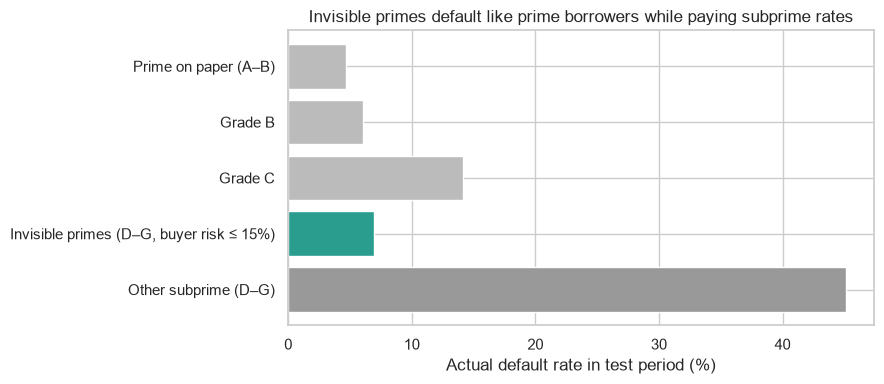

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.barh(
    group_summary.index[::-1],
    100 * group_summary["actual_default_rate"][::-1],
    color=["#999999", "#2a9d8f", "#bbbbbb", "#bbbbbb", "#bbbbbb"]
)

ax.set_xlabel("Actual default rate in test period (%)")
ax.set_title("Invisible primes default like prime borrowers while paying subprime rates")

plt.tight_layout()
plt.show()

In [13]:
print("What the invisible primes look like compared with other D–G borrowers:\n")

profile_columns = [
    "fico_range_low",
    "dti",
    "annual_inc",
    "revol_util",
    "loan_to_income",
    "term_months",
    "mort_acc",
    "int_rate"
]

test.loc[subprime_on_paper].groupby("invisible_prime")[profile_columns].median().T.round(2)

What the invisible primes look like compared with other D–G borrowers:



invisible_prime,False,True
fico_range_low,680.00,685.00
dti,20.82,13.70
annual_inc,62000.00,81000.00
revol_util,53.10,61.50
loan_to_income,0.25,0.07
term_months,36.00,36.00
mort_acc,1.00,2.00
int_rate,20.00,17.99


## Part 2: Pricing view — loans that pay more than their risk justifies

The data does not include actual payments or recoveries, so returns are estimated with a simple model:

- **If repaid:** the lender earns all scheduled payments, `installment × term`, on the `loan_amnt` lent (prepayments are ignored).
- **If defaulted:** the lender loses a fixed share of principal, `LOSS_GIVEN_DEFAULT` (60% by default, with a sensitivity check below).
- Returns are divided by the loan term in years so 36- and 60-month loans are comparable.

Expected return uses a model's predicted default probability. **Realized return** uses what actually happened, which is how the strategies are judged.

In [14]:
LOSS_GIVEN_DEFAULT = 0.60

test["term_years"] = test["term_months"] / 12
test["return_if_repaid"] = test["installment"] * test["term_months"] / test["loan_amnt"] - 1


def annual_realized_return(loans, loss_given_default):
    total_return = np.where(loans[target] == 1, -loss_given_default, loans["return_if_repaid"])
    return total_return / loans["term_years"]


def annual_expected_return(loans, risk_column, loss_given_default):
    default_probability = loans[risk_column]
    total_return = (1 - default_probability) * loans["return_if_repaid"] - default_probability * loss_given_default
    return total_return / loans["term_years"]


test["realized_return"] = annual_realized_return(test, LOSS_GIVEN_DEFAULT)

for model_name, risk_column in risk_columns.items():
    test[f"expected_return_{risk_column}"] = annual_expected_return(test, risk_column, LOSS_GIVEN_DEFAULT)

print(f"Average realized annual return, buying every test loan: {100 * test['realized_return'].mean():.2f}%\n")
print("Average realized annual return by grade:")
print((100 * test.groupby("grade_letter")["realized_return"].mean()).round(2))

Average realized annual return, buying every test loan: 3.22%

Average realized annual return by grade:
grade_letter
A    3.17
B    4.26
C    4.40
D    1.09
E   -0.79
F   -3.86
G   -4.60
Name: realized_return, dtype: float64


Under these assumptions, LendingClub's pricing is not balanced across grades. A–C earn positive returns, while D–G earn roughly nothing or lose money because their higher rates do not fully cover their defaults. **On average, subprime loans are not cheap.** Any opportunity has to come from picking the right loans *within* those grades.

In [15]:
strategy_rows = [{
    "strategy": "Buy every loan",
    "loans_bought": len(test),
    "actual_default_rate": test[target].mean(),
    "realized_annual_return": test["realized_return"].mean()
}]

for model_name, risk_column in risk_columns.items():

    expected_return = test[f"expected_return_{risk_column}"]

    for share_bought in [0.10, 0.20, 0.50]:

        bought = expected_return >= expected_return.quantile(1 - share_bought)

        strategy_rows.append({
            "strategy": f"{model_name}: top {int(100 * share_bought)}% by expected return",
            "loans_bought": bought.sum(),
            "actual_default_rate": test.loc[bought, target].mean(),
            "realized_annual_return": test.loc[bought, "realized_return"].mean()
        })

strategy_results = pd.DataFrame(strategy_rows).set_index("strategy")

strategy_results.round(3)

,loans_bought,actual_default_rate,realized_annual_return
strategy,,,
Buy every loan,93607,0.158,0.032
Grade only: top 10% by expected return,9370,0.187,0.038
Grade only: top 20% by expected return,18787,0.178,0.037
Grade only: top 50% by expected return,46807,0.129,0.038
Borrower-only model: top 10% by expected return,9361,0.210,0.051
Borrower-only model: top 20% by expected return,18722,0.165,0.051
Borrower-only model: top 50% by expected return,46804,0.125,0.046
Buyer's model: top 10% by expected return,9361,0.072,0.070
Buyer's model: top 20% by expected return,18722,0.070,0.063


### Mispriced loans inside subprime grades

The **pricing gap** is the buyer's expected return minus the expected return implied by the loan's grade. A large positive gap means the buyer's model thinks LendingClub priced the loan as riskier than it is, so the interest rate overpays for the risk.

In [16]:
test["pricing_gap"] = test["expected_return_risk_buyer"] - test["expected_return_risk_grade_only"]

subprime_loans = test.loc[subprime_on_paper]

mispricing_rows = [{
    "selection": "All D–G loans",
    "loans": len(subprime_loans),
    "actual_default_rate": subprime_loans[target].mean(),
    "average_int_rate": subprime_loans["int_rate"].mean(),
    "realized_annual_return": subprime_loans["realized_return"].mean()
}]

for share_bought in [0.10, 0.20, 0.30]:

    bought = subprime_loans["pricing_gap"] >= subprime_loans["pricing_gap"].quantile(1 - share_bought)

    mispricing_rows.append({
        "selection": f"Top {int(100 * share_bought)}% of D–G by pricing gap",
        "loans": bought.sum(),
        "actual_default_rate": subprime_loans.loc[bought, target].mean(),
        "average_int_rate": subprime_loans.loc[bought, "int_rate"].mean(),
        "realized_annual_return": subprime_loans.loc[bought, "realized_return"].mean()
    })

prime_loans = test.loc[prime_on_paper]

mispricing_rows.append({
    "selection": "All A–B loans (for comparison)",
    "loans": len(prime_loans),
    "actual_default_rate": prime_loans[target].mean(),
    "average_int_rate": prime_loans["int_rate"].mean(),
    "realized_annual_return": prime_loans["realized_return"].mean()
})

mispricing_results = pd.DataFrame(mispricing_rows).set_index("selection")

mispricing_results.round(3)

,loans,actual_default_rate,average_int_rate,realized_annual_return
selection,,,,
All D–G loans,19702,0.433,21.484,0.000
Top 10% of D–G by pricing gap,1971,0.164,22.784,0.076
Top 20% of D–G by pricing gap,3941,0.181,21.618,0.065
Top 30% of D–G by pricing gap,5911,0.200,21.195,0.058
All A–B loans (for comparison),45003,0.047,9.266,0.039


In [17]:
sensitivity_rows = []

for loss_given_default in [0.40, 0.60, 0.80]:

    realized = annual_realized_return(test, loss_given_default)
    expected = annual_expected_return(test, "risk_buyer", loss_given_default)
    bought = expected >= expected.quantile(0.80)

    sensitivity_rows.append({
        "loss_given_default": loss_given_default,
        "buy_every_loan": realized.mean(),
        "buyer_model_top_20%": realized[bought].mean(),
        "all_A–B_loans": realized[prime_on_paper].mean()
    })

pd.DataFrame(sensitivity_rows).set_index("loss_given_default").round(3)

,buy_every_loan,buyer_model_top_20%,all_A–B_loans
loss_given_default,,,
0.4,0.041,0.068,0.042
0.6,0.032,0.063,0.039
0.8,0.024,0.058,0.036


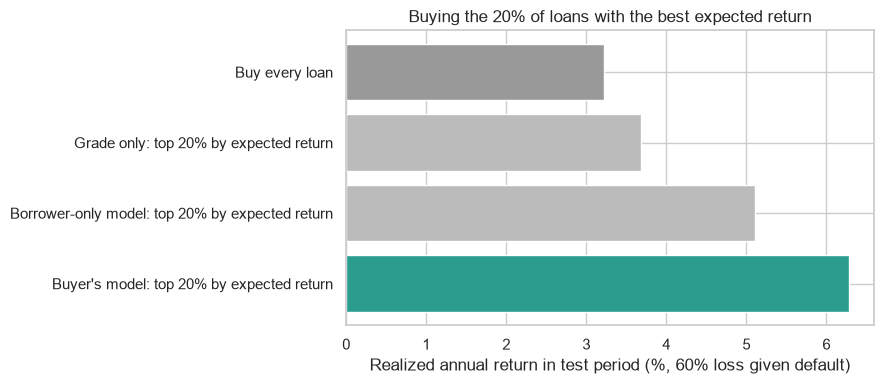

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))

plot_strategies = strategy_results.loc[[
    "Buy every loan",
    "Grade only: top 20% by expected return",
    "Borrower-only model: top 20% by expected return",
    "Buyer's model: top 20% by expected return"
]]

ax.barh(
    plot_strategies.index[::-1],
    100 * plot_strategies["realized_annual_return"][::-1],
    color=["#2a9d8f", "#bbbbbb", "#bbbbbb", "#999999"]
)

ax.set_xlabel("Realized annual return in test period (%, 60% loss given default)")
ax.set_title("Buying the 20% of loans with the best expected return")

plt.tight_layout()
plt.show()

## Conclusions

**Default view.** Loans with the same LendingClub grade differ a lot in real risk: within every grade, the models rank defaults with a ROC-AUC of about 0.66–0.75. Using the buyer's model, D–G loans with predicted risk of 15% or less defaulted at roughly grade B levels while paying subprime interest rates. These are the invisible primes. The group is small (under 1,000 loans, mostly grade D), so it is a niche rather than a large hidden market.

**Ignoring the seller's grade is risky.** The borrower-only model flags many more "safe-looking" D–G borrowers, but they default far more often than prime borrowers. LendingClub's grade contains information the borrower features miss, so the best buyer uses it rather than replacing it.

**Pricing view.** Buying D–G loans blindly earns roughly nothing under these assumptions, but the D–G loans with the largest pricing gap default far less than their grade and earn returns above prime loans. Ranking all loans by the buyer's expected return beats buying every loan and beats ranking by grade alone, and that holds across loss-given-default assumptions from 40% to 80%.

**Caveats before trusting the returns:**

- Returns are estimates: there are no actual payment, prepayment, or recovery columns, and loss given default is an assumption.
- The test set only includes resolved loans, which over-represents early outcomes, especially for 60-month loans.
- Default rates for D–G were higher in the test period than in training, so the predicted probabilities are better used for ranking than as exact percentages.
- The models were tuned once, not cross-validated over time, and the 15% threshold was chosen by looking at the test period. A cleaner version would pick it on a validation period first.